# R1.1: Does the MJS track scenario-level consensus or person-specific moral judgments?

**Reviewer 1, comment 1.** *"The revised manuscript raises an interesting question about whether the MJS primarily captures averaged differences between moral scenarios or individual differences in subjective moral judgments."*

A trial's wrongness rating has two parts:

* **Consensus (scenario) component:** how wrong *people in general* find this vignette. We estimate it as the leave-one-subject-out (LOSO) item mean, so a subject's own rating never enters their consensus score. As a check, we also use the external population norms (US n = 510 for the discovery, validation and replication cohorts; Dutch n = 586 for the generalization cohort).
* **Person-specific (deviation) component:** rating − consensus, i.e. how much more or less wrong *this person* finds *this* vignette than others do.

The input is the trial-wise (LSA) MJS pattern expression computed in `04_validate_mjs_vignettes.ipynb` and saved in `results/sensitivity/{disc,valid,repl,gen}_PE.csv`. Discovery-cohort expressions come from the LOSO cross-validated MJS.

Analyses:
1. **Variance partitioning** of the behavioural ratings (item vs subject).
2. **Within-subject partial correlation** of MJS and rating after removing the consensus (LOSO item mean, or external norms).
3. **Two-way fixed effects:** rating ~ MJS + subject FE + vignette FE, with SEs clustered by subject. The vignette FE remove *all* scenario-level variance.
4. **Mixed model decomposition:** MJS ~ consensus + deviation.
5. **Within-item, across-subject correlation:** for a given vignette, does the person who rates it as more wrong show higher MJS? Uses subject-centred data, tested by permutation.
6. **Between-subject correlation:** overall harshness (mean rating) vs mean MJS.
7. **Moral-only** partial correlations, excluding social-norm vignettes.

The last section re-checks the out-of-sample correlations with the population norms reported in the manuscript (US norms vs discovery cohort; Dutch norms vs generalization cohort).

In [1]:
import numpy as np, pandas as pd, statsmodels.formula.api as smf
from scipy import stats
import os, warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_rows', 200)

BASE = '/srv/lab/fmri/mft/fhopp_diss/analysis/signature/results/sensitivity/'
US_NORMS = '/srv/lab/fmri/mft/mf_duke/behavior/mft_memory/data/mfv_norms.csv'
NL_NORMS = BASE + 'beh_data/hopp_dutch_ratings.csv'
OUT = 'r1_1_output'
os.makedirs(OUT, exist_ok=True)

COHORTS = {'disc': 'Discovery', 'valid': 'Validation', 'repl': 'Replication', 'gen': 'Generalization'}
rng = np.random.default_rng(1)

## Population norms
These norms are fully independent of the fMRI samples. The US norms (Clifford et al.) are the reference for the three US cohorts, and the Dutch norms (Hopp et al., 2024) are the reference for the generalization cohort.

In [2]:
# US norms (n = 510): map file-name prefixes to the vignette labels used in the PE files
us = pd.read_csv(US_NORMS, usecols=['vigfile', 'moral_decision']).dropna()
us_map = {'auth': 'authority', 'careemo': 'care_emotional', 'carephys': 'care_physical', 'fairness': 'fairness',
          'fair': 'fairness', 'lib': 'liberty', 'loy': 'loyalty', 'pur': 'sanctity', 'socnorm': 'social_norms'}
def us_name(v):
    for k in sorted(us_map, key=len, reverse=True):
        if v.startswith(k):
            return us_map[k] + v[len(k):]
    return v
us['vignette'] = us['vigfile'].map(us_name)
us = us.groupby('vignette')['moral_decision'].mean().rename('norm')

# Dutch norms (n = 586)
nl = pd.read_csv(NL_NORMS, index_col=0)
cmap = {'Physical Care': 'care_physical', 'Emotional Care': 'care_emotional', 'Social Norms': 'social_norms'}
nl['vignette'] = nl['Condition'].map(lambda c: cmap.get(c, c.lower())) + nl['item'].str[-2:]
nl = nl.groupby('vignette')['moral wrongness'].mean().rename('norm')

NORMS = {'disc': us, 'valid': us, 'repl': us, 'gen': nl}
print('US norms:', len(us), 'vignettes | Dutch norms:', len(nl), 'vignettes')

US norms: 120 vignettes | Dutch norms: 119 vignettes


## Helper functions

In [3]:
def fisher_mean(rs):
    '''Mean correlation via Fisher z.'''
    rs = np.clip(np.asarray(rs, float), -0.999, 0.999)
    return np.tanh(np.nanmean(np.arctanh(rs)))


def boot_p(x, n=10000):
    '''Two-sided bootstrap p-value for mean(x) != 0 (resampling subjects).'''
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    bs = rng.choice(x, (n, len(x))).mean(1)
    return min(1.0, 2 * min((bs <= 0).mean(), (bs >= 0).mean()) + 1 / n)


def resid(y, x):
    '''Residualise y on x (with intercept).'''
    X = np.c_[np.ones_like(x), x]
    return y - X @ np.linalg.lstsq(X, y, rcond=None)[0]


def zscore(x):
    return (x - x.mean()) / x.std()

## Main analysis

In the fixed-effects model (3), MJS is z-scored **within subject**. Under pooled z-scoring, one discovery subject with very large MJS variance (SD ≈ 5.6) dominates the cluster-robust SE. The pooled-z estimate is kept as `FE_pooledz_*` for reference.

In [4]:
def analyse(tag, n_perm=1000):
    d = pd.read_csv(BASE + f'{tag}_PE.csv', index_col=0).rename(columns={'moral_decision': 'rating', 'mjs_pexp': 'mjs'})
    d = d[['subject', 'vignette', 'rating', 'mjs']].dropna()
    d['cond'] = d['vignette'].str[:-2]

    # Consensus rating: leave-one-subject-out item mean (no circularity)
    g = d.groupby('vignette')['rating']
    d['item_loso'] = (g.transform('sum') - d['rating']) / (g.transform('count') - 1)
    d['dev'] = d['rating'] - d['item_loso']                       # person-specific component
    d = d.join(NORMS[tag], on='vignette')

    out = {'cohort': tag, 'n_sub': d.subject.nunique(), 'n_items': d.vignette.nunique(), 'n_trials': len(d)}

    # 1. Variance partitioning of behaviour
    tot = d['rating'].var(ddof=0)
    out['R2_item'] = 1 - (d['rating'] - d.groupby('vignette')['rating'].transform('mean')).var(ddof=0) / tot
    out['R2_subj'] = 1 - (d['rating'] - d.groupby('subject')['rating'].transform('mean')).var(ddof=0) / tot
    m_add = smf.ols('rating ~ C(subject) + C(vignette)', d).fit()
    out['R2_item+subj'] = m_add.rsquared

    # 2. Within-subject: raw r, partial r controlling consensus (LOSO / external norms)
    rows = []
    for s, ds in d.groupby('subject'):
        r_raw = stats.pearsonr(ds.mjs, ds.rating)[0]
        r_part = stats.pearsonr(resid(ds.mjs.values, ds.item_loso.values), resid(ds.rating.values, ds.item_loso.values))
        ok = ds['norm'].notna()
        r_part_norm = (stats.pearsonr(resid(ds.mjs[ok].values, ds.norm[ok].values),
                                      resid(ds.rating[ok].values, ds.norm[ok].values))[0] if ok.sum() > 10 else np.nan)
        r_item = stats.pearsonr(ds.mjs, ds.item_loso)[0]
        rows.append(dict(subject=s, r_raw=r_raw, r_partial=r_part[0], p_partial=r_part[1],
                         r_partial_norm=r_part_norm, r_mjs_consensus=r_item))
    ws = pd.DataFrame(rows)
    for c in ['r_raw', 'r_mjs_consensus', 'r_partial', 'r_partial_norm']:
        out[f'{c}_mean'] = ws[c].mean(); out[f'{c}_sd'] = ws[c].std()
    out['r_partial_p'] = boot_p(ws.r_partial)
    out['r_partial_t'], out['r_partial_tp'] = stats.ttest_1samp(np.arctanh(ws.r_partial), 0)
    out['r_partial_norm_p'] = boot_p(ws.r_partial_norm)
    zn = np.arctanh(ws.r_partial_norm.dropna())
    out['r_partial_norm_t'], out['r_partial_norm_tp'] = stats.ttest_1samp(zn, 0)
    out['r_partial_norm_df'] = len(zn) - 1
    out['n_sig_partial(p<.05,pos)'] = int(((ws.p_partial < .05) & (ws.r_partial > 0)).sum())
    out['n_pos_partial'] = int((ws.r_partial > 0).sum())

    # 3. Two-way fixed effects: rating ~ MJS + subject FE + vignette FE (cluster-robust SE by subject)
    dz = d.copy()
    groups = pd.factorize(dz.subject)[0]
    dz['mjs_w'] = dz.groupby('subject').mjs.transform(zscore)          # within-subject z (reported)
    m_fe = smf.ols('rating ~ mjs_w + C(subject) + C(vignette)', dz).fit(cov_type='cluster', cov_kwds={'groups': groups})
    out['FE_beta'] = m_fe.params['mjs_w']; out['FE_se'] = m_fe.bse['mjs_w']; out['FE_p'] = m_fe.pvalues['mjs_w']
    out['FE_dR2'] = m_fe.rsquared - m_add.rsquared
    dz['mjs_z'] = zscore(dz.mjs)                                        # pooled z (sensitivity)
    m_fe2 = smf.ols('rating ~ mjs_z + C(subject) + C(vignette)', dz).fit(cov_type='cluster', cov_kwds={'groups': groups})
    out['FE_pooledz_beta'] = m_fe2.params['mjs_z']; out['FE_pooledz_p'] = m_fe2.pvalues['mjs_z']

    # 4. Mixed model: which part of the rating does the MJS carry? MJS ~ consensus + deviation
    dz['item_z'] = zscore(dz.item_loso)
    dz['dev_z'] = zscore(dz.dev)
    m_dec = smf.mixedlm('mjs_z ~ item_z + dev_z', dz, groups=dz['subject'], re_formula='~item_z + dev_z').fit()
    for k in ['item_z', 'dev_z']:
        out[f'MLM_{k}_b'] = m_dec.params[k]; out[f'MLM_{k}_se'] = m_dec.bse[k]; out[f'MLM_{k}_p'] = m_dec.pvalues[k]

    # 5. Within-item, across-subject (subject-centred to remove overall harshness / global offsets)
    dc = d.copy()
    dc['rating_c'] = dc.rating - dc.groupby('subject').rating.transform('mean')
    dc['mjs_c'] = dc.mjs - dc.groupby('subject').mjs.transform('mean')
    grp = [(v, dv) for v, dv in dc.groupby('vignette') if dv.rating.nunique() > 1 and len(dv) > 5]
    ir = pd.DataFrame([(v, stats.pearsonr(dv.mjs_c, dv.rating_c)[0], dv.rating.std()) for v, dv in grp],
                      columns=['vignette', 'r', 'rating_sd'])
    zr = np.arctanh(np.clip(ir.r, -.999, .999))
    out['n_items_var'] = len(ir)
    out['within_item_r_mean'] = fisher_mean(ir.r)
    out['within_item_t'], out['within_item_p'] = stats.ttest_1samp(zr, 0)
    out['within_item_pos'] = int((ir.r > 0).sum())
    # permutation: shuffle ratings across subjects within each vignette
    obs = zr.mean()
    null = [np.mean([np.arctanh(np.clip(np.corrcoef(dv.mjs_c.values, rng.permutation(dv.rating_c.values))[0, 1], -.999, .999))
                     for _, dv in grp]) for _ in range(n_perm)]
    out['within_item_perm_p'] = (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)

    # 6. Between-subject: person-level harshness vs person-level mean MJS
    ps = d.groupby('subject')[['rating', 'mjs']].mean()
    out['between_subj_r'], out['between_subj_p'] = stats.pearsonr(ps.mjs, ps.rating)

    # 7. Moral-only (exclude social-norm vignettes)
    dm = d[d.cond != 'social_norms']
    rr = [stats.pearsonr(resid(ds.mjs.values, ds.item_loso.values), resid(ds.rating.values, ds.item_loso.values))[0]
          for _, ds in dm.groupby('subject')]
    out['r_partial_moralonly_mean'] = np.mean(rr); out['r_partial_moralonly_p'] = boot_p(rr)
    return out, ws, ir

In [5]:
res, within_subj, within_item = [], {}, {}
for tag in COHORTS:
    o, ws, ir = analyse(tag)
    res.append(o); within_subj[tag] = ws; within_item[tag] = ir
    ws.to_csv(f'{OUT}/r1_1_within_subject_{tag}.csv', index=False)
    ir.to_csv(f'{OUT}/r1_1_within_item_{tag}.csv', index=False)
res = pd.DataFrame(res).set_index('cohort').T
res.to_csv(f'{OUT}/r1_1_summary.csv')
res.map(lambda x: f'{x:.3g}' if isinstance(x, (float, np.floating)) else x)

cohort,disc,valid,repl,gen
n_sub,64,30,27,30
n_items,120,72,120,120
n_trials,7.3e+03,2.1e+03,3.16e+03,3.52e+03
R2_item,0.443,0.595,0.415,0.529
R2_subj,0.142,0.0588,0.0852,0.102
R2_item+subj,0.583,0.654,0.498,0.63
r_raw_mean,0.441,0.339,0.167,0.223
r_raw_sd,0.154,0.11,0.124,0.14
r_mjs_consensus_mean,0.318,0.266,0.151,0.17
r_mjs_consensus_sd,0.146,0.0912,0.109,0.119


### Compact table (numbers used in the response letter)

In [6]:
f2, f3 = (lambda x: f'{x:.2f}'), (lambda x: f'{x:.2g}')
tab = pd.DataFrame({
    'n subjects / items': res.loc['n_sub'].astype(int).astype(str) + ' / ' + res.loc['n_items'].astype(int).astype(str),
    '% rating var. item': (100 * res.loc['R2_item']).map(lambda x: f'{x:.0f}'),
    '% rating var. subject': (100 * res.loc['R2_subj']).map(lambda x: f'{x:.0f}'),
    'raw within-subj r': res.loc['r_raw_mean'].map(f2),
    'partial r | LOSO consensus': res.loc['r_partial_mean'].map(f2),
    'subjects r_partial > 0': res.loc['n_pos_partial'].astype(int).astype(str) + '/' + res.loc['n_sub'].astype(int).astype(str),
    'partial r | population norms': res.loc['r_partial_norm_mean'].map(f2),
    'two-way FE beta (p)': res.loc['FE_beta'].map(f2) + ' (' + res.loc['FE_p'].map(f3) + ')',
    'MLM consensus beta': res.loc['MLM_item_z_b'].map(f2),
    'MLM deviation beta': res.loc['MLM_dev_z_b'].map(f2),
    'within-item r (perm p)': res.loc['within_item_r_mean'].map(f2) + ' (' + res.loc['within_item_perm_p'].map(lambda x: f'{x:.3f}') + ')',
    'between-subj harshness r (p)': res.loc['between_subj_r'].map(f2) + ' (' + res.loc['between_subj_p'].map(f2) + ')',
    'partial r, moral-only': res.loc['r_partial_moralonly_mean'].map(f2),
}).T.rename(columns=COHORTS)
tab.to_csv(f'{OUT}/r1_1_table.csv')
tab

cohort,Discovery,Validation,Replication,Generalization
n subjects / items,64 / 120,30 / 72,27 / 120,30 / 120
% rating var. item,44,59,42,53
% rating var. subject,14,6,9,10
raw within-subj r,0.44,0.34,0.17,0.22
partial r | LOSO consensus,0.33,0.22,0.10,0.15
subjects r_partial > 0,64/64,29/30,22/27,27/30
partial r | population norms,0.35,0.24,0.11,0.15
two-way FE beta (p),0.24 (7.7e-80),0.14 (3.3e-16),0.07 (2.2e-07),0.10 (9.7e-11)
MLM consensus beta,0.22,0.23,0.12,0.12
MLM deviation beta,0.26,0.20,0.10,0.12


### Supplementary table
This table has every statistic cited in the Results and the response letter, grouped by analysis. It is saved as `r1_1_SI_table.csv` and `r1_1_SI_table.xlsx` (the xlsx includes the table note). Correlations are group means across participants (partial r) or Fisher-z means across vignettes (within-vignette r).

In [7]:
def p_fmt(p, floor=None):
    if floor is not None and p <= floor:
        return f'≤ {floor:.1g}'   # smallest attainable p for bootstrap / permutation
    return f'{p:.3f}' if p >= .001 else f'{p:.1e}'

def r_(x): return f'{x:.2f}'

si_rows = []
def add(section, measure, fn):
    si_rows.append([section, measure] + [fn(res[c]) for c in COHORTS])

S0 = 'Sample'
add(S0, 'Participants / vignettes', lambda c: f"{int(c.n_sub)} / {int(c.n_items)}")
add(S0, 'Trials', lambda c: f"{int(c.n_trials)}")

S1 = 'Variance partitioning of ratings (η²)'
add(S1, 'Vignette (%)', lambda c: f"{100*c.R2_item:.1f}")
add(S1, 'Participant (%)', lambda c: f"{100*c['R2_subj']:.1f}")
add(S1, 'Vignette + participant, additive (%)', lambda c: f"{100*c['R2_item+subj']:.1f}")
add(S1, 'Residual: participant × vignette + noise (%)', lambda c: f"{100*(1-c['R2_item+subj']):.1f}")

S2 = 'Within-subject MJS–rating correlation'
add(S2, 'Raw r, mean (s.d.)', lambda c: f"{r_(c.r_raw_mean)} ({r_(c.r_raw_sd)})")
add(S2, 'Partial r | LOSO consensus, mean (s.d.)', lambda c: f"{r_(c.r_partial_mean)} ({r_(c.r_partial_sd)})")
add(S2, '   t (df)', lambda c: f"{c.r_partial_t:.2f} ({int(c.n_sub)-1})")
add(S2, '   p, t-test', lambda c: p_fmt(c.r_partial_tp))
add(S2, '   p, bootstrap', lambda c: p_fmt(c.r_partial_p, floor=1e-4))
add(S2, '   participants r > 0 / p < .05 & r > 0', lambda c: f"{int(c.n_pos_partial)} / {int(c['n_sig_partial(p<.05,pos)'])} of {int(c.n_sub)}")
add(S2, 'Partial r | population norms, mean (s.d.)', lambda c: f"{r_(c.r_partial_norm_mean)} ({r_(c.r_partial_norm_sd)})")
add(S2, '   t (df)', lambda c: f"{c.r_partial_norm_t:.2f} ({int(c.r_partial_norm_df)})")
add(S2, '   p, t-test', lambda c: p_fmt(c.r_partial_norm_tp))
add(S2, '   p, bootstrap', lambda c: p_fmt(c.r_partial_norm_p, floor=1e-4))

S3 = 'Two-way fixed effects: rating ~ MJS + participant + vignette'
add(S3, 'b (rating points per s.d. MJS)', lambda c: f"{c.FE_beta:.3f}")
add(S3, '   s.e. (clustered by participant)', lambda c: f"{c.FE_se:.3f}")
add(S3, '   z', lambda c: f"{c.FE_beta/c.FE_se:.2f}")
add(S3, '   p', lambda c: p_fmt(c.FE_p))
add(S3, 'ΔR² beyond participant + vignette (%)', lambda c: f"{100*c.FE_dR2:.2f}")

S4 = 'Within-vignette, across-participant correlation'
add(S4, 'Vignettes analysed', lambda c: f"{int(c.n_items_var)}")
add(S4, 'r, Fisher-z mean', lambda c: r_(c.within_item_r_mean))
add(S4, '   t (df)', lambda c: f"{c.within_item_t:.2f} ({int(c.n_items_var)-1})")
add(S4, '   p, permutation', lambda c: p_fmt(c.within_item_perm_p, floor=1/1001))
add(S4, '   vignettes r > 0', lambda c: f"{int(c.within_item_pos)} of {int(c.n_items_var)}")

S5 = 'Mixed model: MJS ~ consensus + person-specific deviation'
for k, lab in [('item_z', 'Consensus'), ('dev_z', 'Person-specific deviation')]:
    add(S5, f'{lab} β (s.e.)', lambda c, k=k: f"{c[f'MLM_{k}_b']:.3f} ({c[f'MLM_{k}_se']:.3f})")
    add(S5, '   p', lambda c, k=k: p_fmt(c[f'MLM_{k}_p']))

S6 = 'Between-participant: mean rating vs mean MJS'
add(S6, 'r (df)', lambda c: f"{r_(c.between_subj_r)} ({int(c.n_sub)-2})")
add(S6, '   p', lambda c: p_fmt(c.between_subj_p))

si = pd.DataFrame(si_rows, columns=['Analysis', 'Measure'] + list(COHORTS.values()))

SI_NOTE = (
    "Trial-wise MJS pattern expression (discovery: leave-one-subject-out cross-validated) and wrongness ratings (1–4), "
    "one rating per participant × vignette. Consensus = leave-one-subject-out vignette mean within cohort; population norms = "
    "US (n = 510; discovery, validation, replication) or Dutch (n = 586; generalization). η² from one-way models of rating on "
    "vignette or participant. Partial r: per-participant correlation of MJS and rating residualised on the consensus; tested "
    "with one-sample t-tests on Fisher-z values and a two-sided bootstrap over participants (10,000 resamples). Fixed effects: "
    "OLS with participant and vignette dummies, MJS z-scored within participant, cluster-robust s.e. by participant (Wald z). "
    "Within-vignette r: Pearson r across participants after participant-mean centring, Fisher-z averaged; null from 1,000 "
    "permutations of ratings across participants within vignettes (two-sided). Mixed model: pooled-z MJS on z-scored consensus "
    "and deviation, random intercepts and slopes by participant (REML; Wald z). Between-participant: Pearson r of participant means."
)
si.to_csv(f'{OUT}/r1_1_SI_table.csv', index=False)
with pd.ExcelWriter(f'{OUT}/r1_1_SI_table.xlsx') as xw:
    si.to_excel(xw, index=False, sheet_name='Table')
    pd.DataFrame({'Note': [SI_NOTE]}).to_excel(xw, index=False, sheet_name='Note')
print(SI_NOTE)
si

Trial-wise MJS pattern expression (discovery: leave-one-subject-out cross-validated) and wrongness ratings (1–4), one rating per participant × vignette. Consensus = leave-one-subject-out vignette mean within cohort; population norms = US (n = 510; discovery, validation, replication) or Dutch (n = 586; generalization). η² from one-way models of rating on vignette or participant. Partial r: per-participant correlation of MJS and rating residualised on the consensus; tested with one-sample t-tests on Fisher-z values and a two-sided bootstrap over participants (10,000 resamples). Fixed effects: OLS with participant and vignette dummies, MJS z-scored within participant, cluster-robust s.e. by participant (Wald z). Within-vignette r: Pearson r across participants after participant-mean centring, Fisher-z averaged; null from 1,000 permutations of ratings across participants within vignettes (two-sided). Mixed model: pooled-z MJS on z-scored consensus and deviation, random intercepts and slope

,Analysis,Measure,Discovery,Validation,Replication,Generalization
0,Sample,Participants / vignettes,64 / 120,30 / 72,27 / 120,30 / 120
1,Sample,Trials,7301,2095,3159,3517
2,Variance partitioning of ratings (η²),Vignette (%),44.3,59.5,41.5,52.9
3,Variance partitioning of ratings (η²),Participant (%),14.2,5.9,8.5,10.2
4,Variance partitioning of ratings (η²),"Vignette + participant, additive (%)",58.3,65.4,49.8,63.0
5,Variance partitioning of ratings (η²),Residual: participant × vignette + noise (%),41.7,34.6,50.2,37.0
6,Within-subject MJS–rating correlation,"Raw r, mean (s.d.)",0.44 (0.15),0.34 (0.11),0.17 (0.12),0.22 (0.14)
7,Within-subject MJS–rating correlation,"Partial r | LOSO consensus, mean (s.d.)",0.33 (0.13),0.22 (0.13),0.10 (0.10),0.15 (0.12)
8,Within-subject MJS–rating correlation,t (df),18.51 (63),8.96 (29),5.11 (26),6.59 (29)
9,Within-subject MJS–rating correlation,"p, t-test",3.6e-27,7.5e-10,2.5e-05,3.2e-07


## Check: out-of-sample correlations with population norms

The pairing is **US norms ↔ discovery cohort** (LOSO-CV MJS) and **Dutch norms ↔ generalization cohort**.

The US-norm cell in `04_validate_mjs_vignettes.ipynb` loads discovery MJS files but builds its subject list from the *generalization* beta folder (`glob.glob(gen_betas + 'sub*')`). As a result it averages only the 30 discovery subjects whose IDs also exist in the generalization cohort (sub-02 to sub-31). To fix it, build the list from the discovery betas (`disc_betas`) instead. The cell below reproduces both versions.

In [8]:
disc = pd.read_csv(BASE + 'disc_PE.csv', index_col=0)
gen = pd.read_csv(BASE + 'gen_PE.csv', index_col=0)

rows = []
for label, dd, norms in [('Discovery, all subjects (corrected)', disc, us),
                         ('Discovery, only IDs shared with generalization (as in 04)', disc[disc.subject.isin(set(gen.subject))], us),
                         ('Generalization vs Dutch norms', gen, nl)]:
    m = dd.groupby('vignette').mjs_pexp.mean().to_frame().join(norms, how='inner')
    r, p = stats.pearsonr(m.mjs_pexp, m.norm)
    rows.append(dict(analysis=label, n_subjects=dd.subject.nunique(), n_items=len(m), r=round(r, 3), p=f'{p:.2g}'))
pd.DataFrame(rows)

,analysis,n_subjects,n_items,r,p
0,"Discovery, all subjects (corrected)",64,120,0.773,4.2e-25
1,"Discovery, only IDs shared with generalization...",30,120,0.786,2e-26
2,Generalization vs Dutch norms,30,119,0.578,5.6e-12


---
# R1.3: Is the MJS intent-vs-accident effect actually different between NT and ASD participants?

**Reviewer 1, comment 3.** *"The comparison between NT and ASD participants is interesting. However, significant prediction in one group and non-significant prediction in the other does not necessarily establish a group difference. A direct statistical comparison of MJS performance between the two groups would strengthen this conclusion, particularly given the relatively small ASD sample."*

**Original analysis** (`08_sensitivity.ipynb`, study 7, Koster-Hale et al. 2013, ds000212, NT n = 25 and ASD n = 14). The MJS, PINES and VIDS were applied to each participant's intention-phase condition betas. There are 10 conditions: physical harm, psychological harm, incest, pathogen and neutral, each in an intentional and an accidental version. Pattern expression was z-scored across all maps, neutral scenarios were dropped, and expression was averaged within participant for intentional and for accidental scenarios. Forced-choice accuracy is the share of participants whose intentional mean exceeds their accidental mean. Reported results: NT 76%, p = .01; ASD 50%, p = 1.00.

**Direct tests here** (primary outcome: the per-participant difference Δ = intentional − accidental MJS expression):
1. Group difference in Δ: Welch t-test, permutation test (10,000 group-label shuffles), Mann–Whitney U, Hedges' g with a 95% CI, and a JZS Bayes factor (BF₁₀, Cauchy prior r = .707).
2. Group difference in forced-choice accuracy: Fisher's exact test and a permutation test.
3. Condition-level linear mixed model: expression ~ intention × group + domain, with random intercepts and intention slopes by participant. The intention × group interaction is the formal test.
4. Robustness: the same group test controlling for age and gender (the ASD group is older and more male).
5. Sensitivity: the smallest group difference (d) detectable with 80% power at n = 25 vs 14.
6. The same tests for PINES and VIDS, for completeness.
7. Behavioral check: did ASD participants distinguish intentional from accidental harms in their ratings? Ratings are the `key` column in the BIDS events files (1–4; 0 = no response).

In [9]:
import glob, pingouin as pg
from statsmodels.stats.power import TTestIndPower

INT_DIR = '/srv/lab/fmri/mft/intention/'
WMAPS = '/srv/lab/fmri/mft/fhopp_diss/analysis/signature/weightmaps/'
PE13 = f'{OUT}/r1_3_condition_PE.csv'
MODELS = ['MJS', 'PINES', 'VIDS']
rng13 = np.random.default_rng(13)   # separate generator, so the R1.1 results above are unaffected

# Condition-level pattern expression, computed exactly as in 08_sensitivity (dot product with
# row-standardised intention-phase betas). It is cached because loading the 390 maps takes about 2 min.
if not os.path.exists(PE13):
    from nltools.data import Brain_Data
    wm = {'MJS': WMAPS + 'mjs/mjs_weights.nii.gz', 'PINES': WMAPS + 'external/PINES.nii.gz',
          'VIDS': WMAPS + 'external/VIDS.nii'}
    files = sorted(f for f in glob.glob(INT_DIR + 'derivatives/glm/*') if 'whole-trial' not in f)
    pe = pd.DataFrame({'file': files})
    base = pe.file.str.split('/').str[-1]
    pe['subject'] = base.str.split('_').str[0]
    pe['cond'] = base.str.split('_').str[1:3].str.join('_')
    imgs = Brain_Data(files).standardize(axis=1)
    for k, f in wm.items():
        pe[k + '_raw'] = imgs.similarity(Brain_Data(f), method='dot_product')
    pe.drop(columns='file').to_csv(PE13, index=False)

parts = pd.read_csv(INT_DIR + 'participants.tsv', sep='\t').rename(columns={'participant_id': 'subject'})
ia = pd.read_csv(PE13).merge(parts, on='subject')
for m in MODELS:                                      # pooled z-score, as in 08 (a linear rescaling)
    ia[m] = zscore(ia[m + '_raw'])
ia['intent'] = ia.cond.str[-1].map({'I': 1, 'A': 0})
ia['domain'] = ia.cond.str.split('_').str[1].str[:-1].map(
    {'PH': 'physical harm', 'PS': 'psychological harm', 'I': 'incest', 'P': 'pathogen', 'N': 'neutral'})
assert ia.subject.nunique() == 39 and ia.groupby('subject').size().eq(10).all()
ia_moral = ia[ia.domain != 'neutral']

# Per-participant intentional and accidental means, and their difference
S = ia_moral.groupby(['subject', 'group', 'age', 'gender', 'intent'])[MODELS].mean().unstack('intent')
delta = pd.DataFrame({m: S[(m, 1)] - S[(m, 0)] for m in MODELS}).reset_index()
delta.to_csv(f'{OUT}/r1_3_delta_per_participant.csv', index=False)
parts.groupby('group').agg(n=('subject', 'size'), age_mean=('age', 'mean'), age_sd=('age', 'std'),
                           n_male=('gender', lambda g: (g == 'M').sum()))

,n,age_mean,age_sd,n_male
group,,,,
ASD,14,33.357143,7.830975,12
NT,25,28.640000,9.720597,17


### Within-group results (reproducing the manuscript)
Forced-choice accuracy uses a two-sided binomial test; the mean Δ uses a one-sample t-test.

In [10]:
rows = []
for m in MODELS:
    for g in ['NT', 'ASD']:
        x = delta.loc[delta.group == g, m].values
        k = int((x > 0).sum()); t = stats.ttest_1samp(x, 0)
        rows.append(dict(model=m, group=g, n=len(x), fc_correct=k, fc_acc=k / len(x),
                         fc_binom_p=stats.binomtest(k, len(x), .5).pvalue,
                         mean_delta=x.mean(), sd_delta=x.std(ddof=1), dz=x.mean() / x.std(ddof=1),
                         t=t.statistic, df=len(x) - 1, p=t.pvalue))
within13 = pd.DataFrame(rows)
within13.round(3)

,model,group,n,fc_correct,fc_acc,fc_binom_p,mean_delta,sd_delta,dz,t,df,p
0,MJS,NT,25,19,0.760,0.015,0.325,0.532,0.611,3.053,24,0.005
1,MJS,ASD,14,7,0.500,1.000,0.081,0.455,0.179,0.668,13,0.516
2,PINES,NT,25,15,0.600,0.424,0.055,0.510,0.108,0.542,24,0.593
3,PINES,ASD,14,8,0.571,0.791,0.144,0.518,0.277,1.038,13,0.318
4,VIDS,NT,25,9,0.360,0.230,0.046,0.564,0.083,0.413,24,0.684
5,VIDS,ASD,14,8,0.571,0.791,0.103,0.492,0.209,0.783,13,0.448


### Direct group comparisons

In [11]:
def perm_diff(x, is_nt, stat, n=10000):
    """Two-sided permutation p-value for stat(NT) - stat(ASD), shuffling group labels."""
    obs = stat(x[is_nt]) - stat(x[~is_nt])
    null = np.empty(n)
    for i in range(n):
        s = rng13.permutation(is_nt)
        null[i] = stat(x[s]) - stat(x[~s])
    return obs, (np.sum(np.abs(null) >= abs(obs) - 1e-12) + 1) / (n + 1)


def boot_diff_ci(a, b, stat, n=10000):
    """Percentile bootstrap 95% CI for stat(a) - stat(b), resampling within groups."""
    bs = [stat(rng13.choice(a, len(a))) - stat(rng13.choice(b, len(b))) for _ in range(n)]
    return np.percentile(bs, [2.5, 97.5])


acc = lambda v: (v > 0).mean()
grp_rows = []
for m in MODELS:
    x = delta[m].values; is_nt = (delta.group == 'NT').values
    nt, asd = x[is_nt], x[~is_nt]
    welch = stats.ttest_ind(nt, asd, equal_var=False)
    student_t = stats.ttest_ind(nt, asd).statistic
    _, p_perm = perm_diff(x, is_nt, np.mean)
    g = pg.compute_effsize(nt, asd, eftype='hedges')
    g_ci = pg.compute_esci(g, len(nt), len(asd), eftype='hedges')
    acc_diff, p_perm_acc = perm_diff(x, is_nt, acc)
    acc_ci = boot_diff_ci(nt, asd, acc)
    fisher = stats.fisher_exact([[(nt > 0).sum(), (nt <= 0).sum()], [(asd > 0).sum(), (asd <= 0).sum()]])
    mm = smf.mixedlm(f'{m} ~ intent * C(group, Treatment("NT")) + C(domain)', ia_moral,
                     groups='subject', re_formula='~intent').fit(reml=True)
    term = 'intent:C(group, Treatment("NT"))[T.ASD]'
    anc = smf.ols(f'{m} ~ C(group, Treatment("ASD")) + age + C(gender)', delta).fit()
    aterm = 'C(group, Treatment("ASD"))[T.NT]'
    grp_rows.append(dict(
        model=m,
        mean_delta_NT=nt.mean(), mean_delta_ASD=asd.mean(), diff=nt.mean() - asd.mean(),
        welch_t=welch.statistic, welch_df=welch.df, welch_p=welch.pvalue, perm_p=p_perm,
        mwu_p=stats.mannwhitneyu(nt, asd, alternative='two-sided').pvalue,
        hedges_g=g, g_ci_low=g_ci[0], g_ci_high=g_ci[1],
        BF10=float(pg.bayesfactor_ttest(student_t, len(nt), len(asd))),
        acc_NT=acc(nt), acc_ASD=acc(asd), acc_diff=acc_diff, acc_diff_ci_low=acc_ci[0], acc_diff_ci_high=acc_ci[1],
        fisher_OR=fisher.statistic, fisher_p=fisher.pvalue, perm_acc_p=p_perm_acc,
        lmm_interaction_b=mm.params[term], lmm_interaction_se=mm.bse[term], lmm_interaction_z=mm.tvalues[term],
        lmm_interaction_p=mm.pvalues[term],
        ancova_group_b=anc.params[aterm], ancova_group_t=anc.tvalues[aterm], ancova_df=anc.df_resid,
        ancova_group_p=anc.pvalues[aterm]))
group13 = pd.DataFrame(grp_rows).set_index('model').T
group13.to_csv(f'{OUT}/r1_3_group_tests.csv')
group13.map(lambda v: f'{v:.3g}')

model,MJS,PINES,VIDS
mean_delta_NT,0.325,0.0553,0.0465
mean_delta_ASD,0.0812,0.144,0.103
diff,0.244,-0.0883,-0.0565
welch_t,1.51,-0.513,-0.326
welch_df,30.8,26.7,30.3
welch_p,0.142,0.612,0.746
perm_p,0.152,0.608,0.762
mwu_p,0.139,0.714,0.629
hedges_g,0.471,-0.169,-0.103
g_ci_low,-0.21,-0.85,-0.78


### Sensitivity: what group difference could this sample detect?

In [12]:
pw = TTestIndPower()
n_nt, n_asd = (delta.group == 'NT').sum(), (delta.group == 'ASD').sum()
mdd = pw.solve_power(effect_size=None, nobs1=n_nt, ratio=n_asd / n_nt, alpha=.05, power=.8)
g_obs = group13.loc['hedges_g', 'MJS']
pd.Series({'minimum detectable d (80% power, two-sided α = .05)': mdd,
           'observed MJS Hedges g': g_obs,
           'power to detect the observed g': pw.power(g_obs, nobs1=n_nt, ratio=n_asd / n_nt, alpha=.05),
           'n per group for 80% power at observed g': pw.solve_power(g_obs, power=.8, ratio=1, alpha=.05)}).round(2)

minimum detectable d (80% power, two-sided α = .05)     0.96
observed MJS Hedges g                                   0.47
power to detect the observed g                          0.28
n per group for 80% power at observed g                71.59
dtype: float64

### Behavioral check: do ASD participants distinguish intentional from accidental harms in their ratings?
Ratings are on a 1–4 scale (higher = more forbidden). Eight participants (3 NT, 5 ASD) have no recorded responses (all `key` = 0), so this check covers a subset.

In [13]:
ev = []
for f in sorted(glob.glob(INT_DIR + 'sub-*/func/*task-dis*events.tsv')):
    e = pd.read_csv(f, sep='\t'); e['subject'] = f.split('/')[-1].split('_')[0]; ev.append(e)
ev = pd.concat(ev).merge(parts, on='subject')
no_resp = ev.groupby(['subject', 'group']).key.apply(lambda k: (k == 0).all())
print('Participants without any recorded response:', no_resp[no_resp].reset_index().groupby('group').subject.apply(list).to_dict())

ev = ev[ev.key > 0].copy()
ev['intent'] = ev.condition.str[-1].map({'I': 1, 'A': 0})
ev_moral = ev[~ev.condition.isin(['E_NA', 'J_NI'])]
beh = ev_moral.groupby(['subject', 'group', 'intent']).key.mean().unstack('intent')
beh.columns = ['rating_accidental', 'rating_intentional']
beh['delta_rating'] = beh.rating_intentional - beh.rating_accidental
beh = beh.reset_index()

brows = []
for g in ['NT', 'ASD']:
    b = beh[beh.group == g]; t = stats.ttest_1samp(b.delta_rating, 0)
    brows.append(dict(group=g, n=len(b), accidental=b.rating_accidental.mean(), intentional=b.rating_intentional.mean(),
                      delta=b.delta_rating.mean(), sd=b.delta_rating.std(), t=t.statistic, p=t.pvalue))
w = stats.ttest_ind(beh.loc[beh.group == 'NT', 'delta_rating'], beh.loc[beh.group == 'ASD', 'delta_rating'], equal_var=False)
display(pd.DataFrame(brows).round(3))
print(f'Group difference in behavioral Δ: Welch t({w.df:.1f}) = {w.statistic:.2f}, p = {w.pvalue:.3f}')

# Brain-behavior link across participants with ratings
bb = beh.merge(delta, on=['subject', 'group'])
r, p = stats.pearsonr(bb.delta_rating, bb.MJS)
print(f'Across participants (n = {len(bb)}): behavioral Δ vs MJS Δ, r = {r:.2f}, p = {p:.3f}')
beh.to_csv(f'{OUT}/r1_3_behavior_per_participant.csv', index=False)

Participants without any recorded response: {'ASD': ['sub-18', 'sub-24', 'sub-29', 'sub-30', 'sub-31'], 'NT': ['sub-14', 'sub-28', 'sub-32']}


,group,n,accidental,intentional,delta,sd,t,p
0,NT,22,1.619,3.102,1.483,0.446,15.604,0.0
1,ASD,9,1.799,3.325,1.525,0.417,10.964,0.0


Group difference in behavioral Δ: Welch t(15.9) = -0.25, p = 0.804
Across participants (n = 31): behavioral Δ vs MJS Δ, r = 0.11, p = 0.573


### Figure (Supplementary): per-participant MJS intentional − accidental difference by group

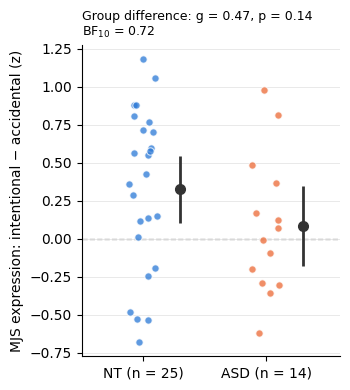

In [14]:
import matplotlib.pyplot as plt
COL = {'NT': '#2a78d6', 'ASD': '#eb6834'}
fig, ax = plt.subplots(figsize=(3.6, 4))
for i, g in enumerate(['NT', 'ASD']):
    x = delta.loc[delta.group == g, 'MJS'].values
    jit = rng13.uniform(-.12, .12, len(x))
    ax.scatter(np.full(len(x), i) + jit, x, s=28, color=COL[g], alpha=.75, edgecolor='white', linewidth=.8, zorder=3)
    ci = stats.t.ppf(.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    ax.errorbar(i + .3, x.mean(), yerr=ci, fmt='o', color='#333333', ms=7, capsize=0, lw=2, zorder=4)
ax.axhline(0, color='#999999', lw=1, ls='--', zorder=1)
ax.set_xticks([0, 1], [f'NT (n = {n_nt})', f'ASD (n = {n_asd})'])
ax.set_xlim(-.5, 1.6)
ax.set_ylabel('MJS expression: intentional − accidental (z)')
r_ = group13['MJS']
ax.set_title(f"Group difference: g = {r_.hedges_g:.2f}, p = {r_.welch_p:.2f}\nBF$_{{10}}$ = {r_.BF10:.2f}", fontsize=9, loc='left')
for s in ['top', 'right']: ax.spines[s].set_visible(False)
ax.grid(axis='y', color='#e5e5e5', lw=.6, zorder=0)
plt.tight_layout()
plt.savefig(f'{OUT}/r1_3_delta_by_group.png', dpi=300, bbox_inches='tight')
plt.show()

### R1.3 summary

| | NT (n = 25) | ASD (n = 14) | Direct group test |
|---|---|---|---|
| MJS forced-choice accuracy | 76% (19/25), binomial p = .015 | 50% (7/14), p = 1.00 | Δacc = 26 points, 95% bootstrap CI [−6, 56]; Fisher p = .16; permutation p = .16 |
| MJS Δ (intentional − accidental, z) | 0.33, t(24) = 3.05, p = .005, d_z = 0.61 | 0.08, t(13) = 0.67, p = .52, d_z = 0.18 | Welch t(30.8) = 1.51, p = .14; permutation p = .15; Mann–Whitney p = .14; g = 0.47 [−0.21, 1.16]; BF₁₀ = 0.72 |
| Mixed model (intention × group) | | | b = −0.24, SE = 0.17, z = −1.44, p = .15 |
| Controlling for age and gender | | | t(35) = 1.46, p = .15 |
| PINES / VIDS Δ group difference | | | p = .61 / .75 |
| Behavior: rating Δ (1–4 scale) | 1.48 (n = 22) | 1.53 (n = 9) | Welch t(15.9) = −0.25, p = .80 |

**Interpretation.** The reviewer is right. The MJS separated intentional from accidental harms in NT participants and not in ASD participants, and the effect was numerically about four times larger in NT participants. However, the direct comparison between groups was **not significant** in any test, and the Bayes factor (0.72) is inconclusive: it favours neither a difference nor its absence. With n = 25 vs 14, the design has 80% power only for a group difference of d ≈ 0.96. The observed g = 0.47 would need about 72 participants per group. In addition, ASD participants distinguished intentional from accidental harms in their ratings as strongly as NT participants did (in the 31 participants with recorded responses), and individual differences in behavioral discrimination were unrelated to MJS discrimination (r = .11, p = .57; the behavioral effect is near ceiling).

**Consequence for the manuscript.** The claim that participants with ASD "rely on fundamentally different neural systems" is not supported and should be removed. The NT result can stay as a validation of the MJS's sensitivity to intent. The ASD result should be reported as exploratory: a weaker, non-significant effect whose difference from NT could not be established with this sample.

---
# R1.4: Do neural patterns for the four wrongness ratings have an ordinal structure? (RSA)

**Reviewer 1, comment 4.** *"Given the emphasis on graded moral wrongness, it would be interesting to examine whether the neural representations of the four rating levels exhibit an ordinal structure. For example, are neural patterns associated with adjacent ratings (eg, 1&2) more similar than those associated with more distant ratings (1&3 or 1&4)? A representational similarity analysis might provide additional insight into how gradations of moral wrongness are organized in neural representational space."*

**Approach.** For each participant in the four vignette cohorts, we take the four whole-brain rating-level beta maps that the MJS was trained on (`{sub}_vig_common_rating_{1-4}_smooth8_scaled`). From these we build a 4 × 4 representational dissimilarity matrix (RDM), with dissimilarity = 1 − Pearson r between two rating maps. The RSA uses the activity patterns only, not the MJS weights.

Tests within each cohort (two-sided, across participants):
1. **Ordinal model.** Kendall's τ_a (Nili et al., 2014) between each participant's six dissimilarities and the ordinal model RDM, where dissimilarity = |i − j|. Tested against 0 with a one-sample t-test (Wilcoxon signed-rank as a check).
2. **Adjacent vs more distant ratings.** Paired t-tests of the mean dissimilarity of adjacent pairs (lag 1: 1–2, 2–3, 3–4) against pairs two steps apart (lag 2: 1–3, 2–4) and three steps apart (lag 3: 1–4), and of lag 2 against lag 3.
3. **The reviewer's example.** d(1,2) < d(1,3) and d(1,2) < d(1,4), plus d(1,3) < d(1,4). For symmetry, the same comparisons anchored at rating 4: d(3,4) < d(2,4), d(3,4) < d(1,4) and d(2,4) < d(1,4).

Participants without trials for one of the four ratings have no complete RDM and are excluded.

In [15]:
import itertools
from nltools.data import Brain_Data

SIG = '/srv/lab/fmri/mft/fhopp_diss/analysis/signature/'
GLM_DIR = {'disc': 'ucsb_1', 'valid': 'ucsb_2', 'repl': 'duke', 'gen': 'uva'}
PAIRS = list(itertools.combinations(range(4), 2))          # (0,1)=1-2, 1-3, 1-4, 2-3, 2-4, 3-4
PL = [f'{i + 1}-{j + 1}' for i, j in PAIRS]
LAG = np.array([j - i for i, j in PAIRS])
RDM_F = f'{OUT}/r1_4_rdms.csv'


def rating_rdm(tag, sub):
    """Correlation distance between a participant's four rating-level MJS training maps (None if a rating is missing)."""
    files = [f'{SIG}results/glm/{GLM_DIR[tag]}/{sub}_vig_common_rating_{r}_smooth8_scaled.nii.gz' for r in range(1, 5)]
    if not all(os.path.exists(f) for f in files):
        return None
    D = 1 - np.corrcoef(Brain_Data(files).data)
    return {p: D[i, j] for p, (i, j) in zip(PL, PAIRS)}


if os.path.exists(RDM_F):
    rdm = pd.read_csv(RDM_F)
else:
    rows = []
    for tag in COHORTS:
        for sub in sorted(pd.read_csv(f'{BASE}{tag}_PE.csv', usecols=['subject']).subject.unique()):
            d = rating_rdm(tag, sub)
            rows.append(dict(cohort=tag, subject=sub, complete=d is not None, **(d or {})))
    rdm = pd.DataFrame(rows)
    rdm.to_csv(RDM_F, index=False)

print('Excluded (missing a rating level):', rdm.loc[~rdm.complete, ['cohort', 'subject']].values.tolist())
rdm = rdm[rdm.complete].reset_index(drop=True)
rdm.groupby('cohort').size().loc[list(COHORTS)].rename('n participants')

Excluded (missing a rating level): [['valid', 'sub-13']]


cohort
disc     64
valid    29
repl     27
gen      30
Name: n participants, dtype: int64

In [16]:
def tau_a(x, y):
    """Kendall's tau-a (ties count as 0; recommended for model RDMs with ties, Nili et al. 2014)."""
    sx = np.sign(x[:, None] - x[None, :]); sy = np.sign(y[:, None] - y[None, :])
    iu = np.triu_indices(len(x), 1)
    return (sx[iu] * sy[iu]).mean()


def one_sample(x):
    t = stats.ttest_1samp(x, 0)
    return dict(mean=x.mean(), sd=x.std(ddof=1), t=t.statistic, df=len(x) - 1, p=t.pvalue,
                dz=x.mean() / x.std(ddof=1), p_wilcoxon=stats.wilcoxon(x).pvalue, pct_pos=100 * (x > 0).mean())


ORDINAL = LAG.astype(float)
stats14 = []
for tag in COHORTS:
    D = rdm.loc[rdm.cohort == tag, PL].values
    d = {p: D[:, PL.index(p)] for p in PL}
    lag = {k: D[:, LAG == k].mean(1) for k in (1, 2, 3)}
    tau = np.array([tau_a(row, ORDINAL) for row in D])
    tests = {  # a positive value supports an ordinal structure
        'Ordinal model (τa)': tau,
        'lag 2 > lag 1': lag[2] - lag[1],
        'lag 3 > lag 1': lag[3] - lag[1],
        'lag 3 > lag 2': lag[3] - lag[2],
        'd(1,3) > d(1,2)': d['1-3'] - d['1-2'],
        'd(1,4) > d(1,2)': d['1-4'] - d['1-2'],
        'd(1,4) > d(1,3)': d['1-4'] - d['1-3'],
        'd(2,4) > d(3,4)': d['2-4'] - d['3-4'],
        'd(1,4) > d(3,4)': d['1-4'] - d['3-4'],
        'd(1,4) > d(2,4)': d['1-4'] - d['2-4'],
    }
    for name, x in tests.items():
        stats14.append(dict(cohort=tag, test=name, n=len(D), **one_sample(x)))
    stats14.append(dict(cohort=tag, test='mean d, lag 1 / 2 / 3', n=len(D),
                        lags=' / '.join(f'{lag[k].mean():.3f}' for k in (1, 2, 3))))
stats14 = pd.DataFrame(stats14)
stats14.to_csv(f'{OUT}/r1_4_rsa_statistics.csv', index=False)

fp = lambda p: f'{p:.3f}' if p >= .001 else f'{p:.0e}'
def cell(s):
    if isinstance(s.get('lags'), str):
        return s.lags
    star = '***' if s.p < .001 else '**' if s.p < .01 else '*' if s.p < .05 else ''
    lead = f'τa = {s["mean"]:.2f}, ' if s.test.startswith('Ordinal') else ''
    return f'{lead}t({s.df:.0f}) = {s.t:.2f}, p = {fp(s.p)}{star}'

tab14 = (stats14.assign(cell=stats14.apply(cell, axis=1))
         .pivot(index='test', columns='cohort', values='cell')
         .loc[list(dict.fromkeys(stats14.test)), list(COHORTS)]
         .rename(columns={k: f'{v} (n = {stats14[stats14.cohort == k].n.iloc[0]})' for k, v in COHORTS.items()}))
tab14.index.name = None
tab14.to_csv(f'{OUT}/r1_4_SI_table.csv')
tab14

cohort,Discovery (n = 64),Validation (n = 29),Replication (n = 27),Generalization (n = 30)
Ordinal model (τa),"τa = 0.30, t(63) = 10.65, p = 1e-15***","τa = 0.17, t(28) = 2.64, p = 0.013*","τa = 0.39, t(26) = 6.74, p = 4e-07***","τa = 0.24, t(29) = 4.80, p = 4e-05***"
lag 2 > lag 1,"t(63) = 12.75, p = 4e-19***","t(28) = 3.80, p = 7e-04***","t(26) = 5.19, p = 2e-05***","t(29) = 5.63, p = 4e-06***"
lag 3 > lag 1,"t(63) = 5.44, p = 9e-07***","t(28) = 2.26, p = 0.032*","t(26) = 4.25, p = 2e-04***","t(29) = 1.74, p = 0.093"
lag 3 > lag 2,"t(63) = -0.41, p = 0.684","t(28) = 0.83, p = 0.411","t(26) = 3.01, p = 0.006**","t(29) = 0.29, p = 0.776"
"d(1,3) > d(1,2)","t(63) = 1.11, p = 0.272","t(28) = -0.68, p = 0.501","t(26) = 0.73, p = 0.473","t(29) = 0.94, p = 0.353"
"d(1,4) > d(1,2)","t(63) = 1.07, p = 0.288","t(28) = -0.42, p = 0.677","t(26) = 2.72, p = 0.011*","t(29) = 0.97, p = 0.339"
"d(1,4) > d(1,3)","t(63) = 0.30, p = 0.764","t(28) = 0.32, p = 0.749","t(26) = 2.63, p = 0.014*","t(29) = -0.05, p = 0.962"
"d(2,4) > d(3,4)","t(63) = 5.21, p = 2e-06***","t(28) = 2.68, p = 0.012*","t(26) = 3.60, p = 0.001**","t(29) = 0.81, p = 0.426"
"d(1,4) > d(3,4)","t(63) = 3.53, p = 8e-04***","t(28) = 2.24, p = 0.033*","t(26) = 4.80, p = 6e-05***","t(29) = 1.33, p = 0.194"
"d(1,4) > d(2,4)","t(63) = -0.81, p = 0.419","t(28) = 0.90, p = 0.376","t(26) = 3.30, p = 0.003**","t(29) = 1.00, p = 0.324"


### Figure: representational geometry of the four wrongness ratings
Top: group-mean RDMs (correlation distance, 1 − r, between rating maps; each cohort has its own colour scale). Bottom: the reviewer's comparison. Dissimilarity of rating 1 to ratings 2, 3 and 4 (blue), and of rating 4 to ratings 3, 2 and 1 (orange), plotted against the number of rating steps apart. Each participant's six dissimilarities are centred on that participant's mean before averaging, so the error bars (95% CI) reflect the within-participant comparisons that are tested above. An ordinal structure predicts both lines rise from left to right.

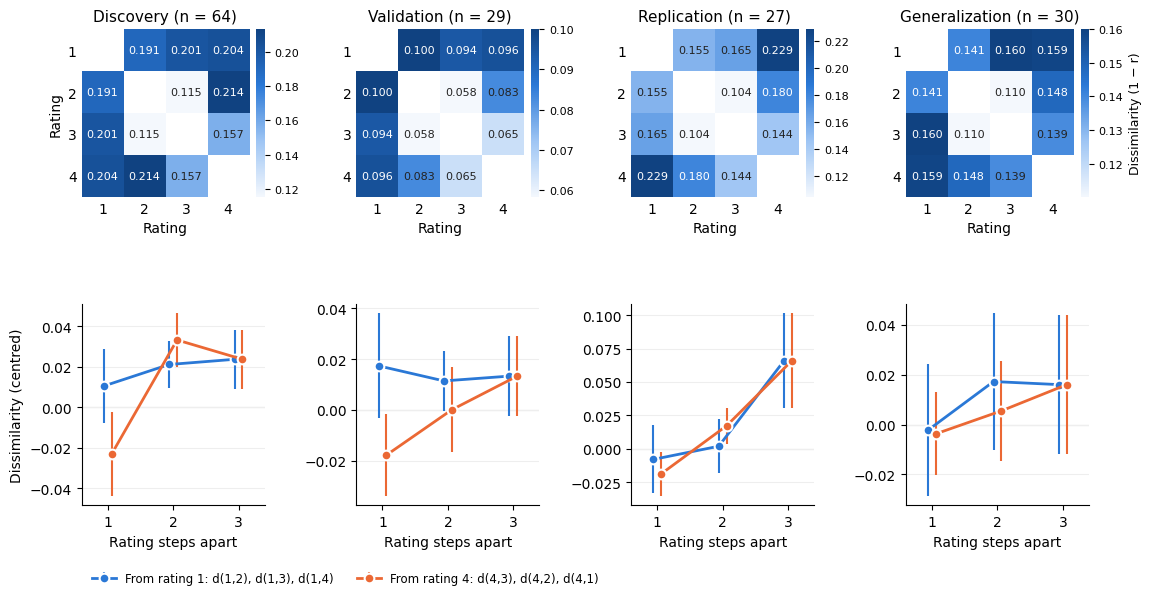

In [17]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SEQ = LinearSegmentedColormap.from_list('seq', ['#f4f8fd', '#9ec5f4', '#2a78d6', '#104281'])
ANCHOR = {'From rating 1: d(1,2), d(1,3), d(1,4)': (['1-2', '1-3', '1-4'], '#2a78d6', -0.06),
          'From rating 4: d(4,3), d(4,2), d(4,1)': (['3-4', '2-4', '1-4'], '#eb6834', 0.06)}

fig, axes = plt.subplots(2, 4, figsize=(13, 6.4), gridspec_kw=dict(height_ratios=[1, 1], hspace=.45, wspace=.5))
for c, tag in enumerate(COHORTS):
    D = rdm.loc[rdm.cohort == tag, PL]
    M = np.full((4, 4), np.nan)
    for p, (i, j) in zip(PL, PAIRS):
        M[i, j] = M[j, i] = D[p].mean()
    ax = axes[0, c]
    im = ax.imshow(M, cmap=SEQ, vmin=np.nanmin(M), vmax=np.nanmax(M))
    for i in range(4):
        for j in range(4):
            if i != j:
                light = (M[i, j] - np.nanmin(M)) / (np.nanmax(M) - np.nanmin(M)) > .6
                ax.text(j, i, f'{M[i, j]:.3f}', ha='center', va='center', fontsize=8, color='white' if light else '#222')
    ax.set_xticks(range(4), [1, 2, 3, 4]); ax.set_yticks(range(4), [1, 2, 3, 4])
    ax.set_xlabel('Rating'); ax.set_ylabel('Rating' if c == 0 else '')
    ax.set_title(f'{COHORTS[tag]} (n = {len(D)})', fontsize=11)
    cb = fig.colorbar(im, ax=ax, fraction=.046, pad=.04)
    cb.ax.tick_params(labelsize=8); cb.outline.set_visible(False)
    if c == 3:
        cb.set_label('Dissimilarity (1 − r)', fontsize=9)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

    ax = axes[1, c]
    Dc = D.values - D.values.mean(1, keepdims=True)
    for label, (pairs, col, off) in ANCHOR.items():
        X = Dc[:, [PL.index(p) for p in pairs]]
        m, ci = X.mean(0), stats.t.ppf(.975, len(X) - 1) * X.std(0, ddof=1) / np.sqrt(len(X))
        ax.errorbar(np.arange(1, 4) + off, m, yerr=ci, color=col, lw=2, marker='o', ms=7, capsize=0,
                    elinewidth=1.5, mec='white', mew=1.5, label=label)
    ax.axhline(0, color='#bbb', lw=.8, zorder=0)
    ax.set_xticks([1, 2, 3]); ax.set_xlim(.6, 3.4)
    ax.set_xlabel('Rating steps apart')
    ax.set_ylabel('Dissimilarity (centred)' if c == 0 else '')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#eee', lw=.8); ax.set_axisbelow(True)
axes[1, 0].legend(frameon=False, fontsize=8.5, loc='upper left', bbox_to_anchor=(0, -0.28), ncol=2)
fig.savefig(f'{OUT}/r1_4_rsa_geometry.png', dpi=300, bbox_inches='tight')
plt.show()

### R1.4 summary

| | Discovery (64) | Validation (29) | Replication (27) | Generalization (30) |
|---|---|---|---|---|
| Ordinal model, τa | .30, p = 1e-15 | .17, p = .013 | .39, p = 4e-7 | .24, p = 4e-5 |
| Mean d, lag 1 / 2 / 3 | .154 / .207 / .204 | .074 / .088 / .096 | .134 / .172 / .229 | .130 / .154 / .159 |
| Lag 2 > lag 1 | p = 4e-19 | p = 7e-4 | p = 2e-5 | p = 4e-6 |
| Lag 3 > lag 1 | p = 9e-7 | p = .032 | p = 2e-4 | p = .093 |
| Lag 3 > lag 2 | n.s. | n.s. | p = .006 | n.s. |
| d(1,3) > d(1,2); d(1,4) > d(1,2) | n.s.; n.s. | n.s.; n.s. | n.s.; p = .011 | n.s.; n.s. |
| d(2,4) > d(3,4); d(1,4) > d(3,4) | p = 2e-6; p = 8e-4 | p = .012; p = .033 | p = .001; p = 6e-5 | n.s.; n.s. |

* **Ordinal structure: yes.** The ordinal model fits the rating-level patterns in all four cohorts. Adjacent ratings are more similar than ratings two steps apart in every cohort, and more similar than ratings three steps apart in three of four cohorts.
* **But it saturates.** Dissimilarity does not grow from two to three steps, except in the replication cohort. Ratings 2 and 3 are the most similar pair in every cohort, which contributes much of the lag-1 vs lag-2 difference.
* **The reviewer's example (anchored at rating 1) is not supported.** Rating 1 is about equally distinct from ratings 2, 3 and 4 (the only exception is d(1,4) > d(1,2) in replication). Anchored at rating 4, the predicted order holds in discovery, validation and replication: d(3,4) < d(2,4) and d(3,4) < d(1,4). So the gradation is clearest among the levels at which acts are judged wrong (2–4).